In [1]:
from pathlib import Path
import ast
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

PTBXL_DIR = PROJECT_ROOT / "data/raw/ptb-xl"
OUTPUT_DIR = PROJECT_ROOT / "data/processed/ptb-xl"

METADATA_FILE = PTBXL_DIR / "ptbxl_database.csv"
STATEMENTS_FILE = PTBXL_DIR / "scp_statements.csv"

CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]

In [2]:
metadata = pd.read_csv(METADATA_FILE)
statements = pd.read_csv(STATEMENTS_FILE, index_col=0)

print("PTB-XL metadata shape:", metadata.shape)
print("SCP statement mapping shape:", statements.shape)

print("\nMetadata preview:")
display(metadata.head())

print("\nSCP statement mapping preview:")
display(statements.head())

print("\nRecords in each official fold:")
display(metadata["strat_fold"].value_counts().sort_index().to_frame("Records"))

PTB-XL metadata shape: (21799, 28)
SCP statement mapping shape: (71, 12)

Metadata preview:


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,scp_codes,heart_axis,infarction_stadium1,infarction_stadium2,validated_by,second_opinion,initial_autogenerated_report,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.000,56.000,1,NaN,63.000,2.000,0.000,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.000,19.000,0,NaN,70.000,2.000,0.000,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,"{'NORM': 80.0, 'SBRAD': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.000,37.000,1,NaN,69.000,2.000,0.000,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr
3,4,17014.000,24.000,0,NaN,82.000,2.000,0.000,CS-12 E,1984-11-15 13:44:57,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,", II,III,AVF",NaN,NaN,NaN,NaN,NaN,3,records100/00000/00004_lr,records500/00000/00004_hr
4,5,17448.000,19.000,1,NaN,70.000,2.000,0.000,CS-12 E,1984-11-17 10:43:15,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,", III,AVR,AVF",NaN,NaN,NaN,NaN,NaN,4,records100/00000/00005_lr,records500/00000/00005_hr



SCP statement mapping preview:


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
NDT,non-diagnostic T abnormalities,1.000,1.000,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.000,1.000,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnorm...,non-specific ST changes,145.000,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.000,1.000,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.000,NaN,NaN,NaN
LNGQT,long QT-interval,1.000,1.000,NaN,STTC,STTC,other ST-T descriptive statements,long QT-interval,148.000,NaN,NaN,NaN
NORM,normal ECG,1.000,NaN,NaN,NORM,NORM,Normal/abnormal,normal ECG,1.000,NaN,NaN,F-000B7



Records in each official fold:


,Records
strat_fold,
1,2175
2,2181
3,2192
4,2174
5,2174
6,2173
7,2176
8,2173
9,2183


In [3]:
# Keep only codes officially marked as diagnostic statements.
diagnostic_statements = statements[
    (statements["diagnostic"] == 1)
    & (statements["diagnostic_class"].notna())
].copy()

# Example: "IMI" -> "MI", "NORM" -> "NORM"
code_to_class = diagnostic_statements["diagnostic_class"].to_dict()

def extract_diagnostic_classes(scp_codes_text):
    """Convert a PTB-XL SCP-code dictionary into diagnostic superclasses."""
    scp_codes = ast.literal_eval(scp_codes_text)

    classes = {
        code_to_class[code]
        for code in scp_codes
        if code in code_to_class
    }

    return sorted(classes)

before_label_filter = metadata.copy()

metadata["diagnostic_classes"] = metadata["scp_codes"].apply(
    extract_diagnostic_classes
)

labelled_metadata = metadata[
    metadata["diagnostic_classes"].str.len() > 0
].copy()

for class_name in CLASSES:
    labelled_metadata[class_name] = labelled_metadata["diagnostic_classes"].apply(
        lambda labels: int(class_name in labels)
    )

comparison = pd.DataFrame(
    {
        "Before label preparation": [
            len(before_label_filter),
            0,
        ],
        "After label preparation": [
            len(labelled_metadata),
            len(labelled_metadata[CLASSES].sum(axis=1).gt(0)),
        ],
    },
    index=["ECG records", "Records with at least one diagnostic label"],
)

print("Before vs after diagnostic-label preparation:")
display(comparison)

print("\nDiagnostic-superclass prevalence:")
display(
    labelled_metadata[CLASSES]
    .sum()
    .sort_values(ascending=False)
    .to_frame("Number of ECGs")
)

print("\nExample converted labels:")
display(
    labelled_metadata[
        ["ecg_id", "scp_codes", "diagnostic_classes"] + CLASSES
    ].head(10)
)

Before vs after diagnostic-label preparation:


,Before label preparation,After label preparation
ECG records,21799,21388
Records with at least one diagnostic label,0,21388



Diagnostic-superclass prevalence:


,Number of ECGs
NORM,9514
MI,5469
STTC,5235
CD,4898
HYP,2649



Example converted labels:


,ecg_id,scp_codes,diagnostic_classes,NORM,MI,STTC,CD,HYP
0,1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",[NORM],1,0,0,0,0
1,2,"{'NORM': 80.0, 'SBRAD': 0.0}",[NORM],1,0,0,0,0
2,3,"{'NORM': 100.0, 'SR': 0.0}",[NORM],1,0,0,0,0
3,4,"{'NORM': 100.0, 'SR': 0.0}",[NORM],1,0,0,0,0
4,5,"{'NORM': 100.0, 'SR': 0.0}",[NORM],1,0,0,0,0
5,6,"{'NORM': 100.0, 'SR': 0.0}",[NORM],1,0,0,0,0
6,7,"{'NORM': 100.0, 'SR': 0.0}",[NORM],1,0,0,0,0
7,8,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}",[MI],0,1,0,0,0
8,9,"{'NORM': 100.0, 'SR': 0.0}",[NORM],1,0,0,0,0
9,10,"{'NORM': 100.0, 'SR': 0.0}",[NORM],1,0,0,0,0


In [4]:
before_split = labelled_metadata.copy()

labelled_metadata["split"] = np.select(
    [
        labelled_metadata["strat_fold"].between(1, 8),
        labelled_metadata["strat_fold"] == 9,
        labelled_metadata["strat_fold"] == 10,
    ],
    [
        "train",
        "validation",
        "test",
    ],
    default="unknown",
)

assert (labelled_metadata["split"] == "unknown").sum() == 0

split_summary = (
    labelled_metadata
    .groupby("split")
    .agg(
        records=("ecg_id", "count"),
        unique_patients=("patient_id", "nunique"),
        normal_ecgs=("NORM", "sum"),
        myocardial_infarction=("MI", "sum"),
    )
    .reindex(["train", "validation", "test"])
)

print("Before vs after split assignment:")
display(
    pd.DataFrame(
        {
            "Before": [len(before_split)],
            "After": [len(labelled_metadata)],
        },
        index=["Total labelled ECG records"],
    )
)

print("\nSplit summary:")
display(split_summary)

train_patients = set(
    labelled_metadata.loc[labelled_metadata["split"] == "train", "patient_id"]
)
validation_patients = set(
    labelled_metadata.loc[labelled_metadata["split"] == "validation", "patient_id"]
)
test_patients = set(
    labelled_metadata.loc[labelled_metadata["split"] == "test", "patient_id"]
)

patient_overlap = pd.DataFrame(
    {
        "Patient overlap": [
            len(train_patients & validation_patients),
            len(train_patients & test_patients),
            len(validation_patients & test_patients),
        ]
    },
    index=[
        "Train ∩ validation",
        "Train ∩ test",
        "Validation ∩ test",
    ],
)

print("\nPatient-leakage check — every value should be 0:")
display(patient_overlap)

Before vs after split assignment:


,Before,After
Total labelled ECG records,21388,21388



Split summary:


,records,unique_patients,normal_ecgs,myocardial_infarction
split,,,,
train,17084,14823,7596,4379
validation,2146,1917,955,540
test,2158,1877,963,550



Patient-leakage check — every value should be 0:


,Patient overlap
Train ∩ validation,0
Train ∩ test,0
Validation ∩ test,0


ECG ID: 1
Labels: ['NORM']
Signal shape: (1000, 12)
Expected shape: (1000 time points, 12 leads)
Contains missing signal values: False


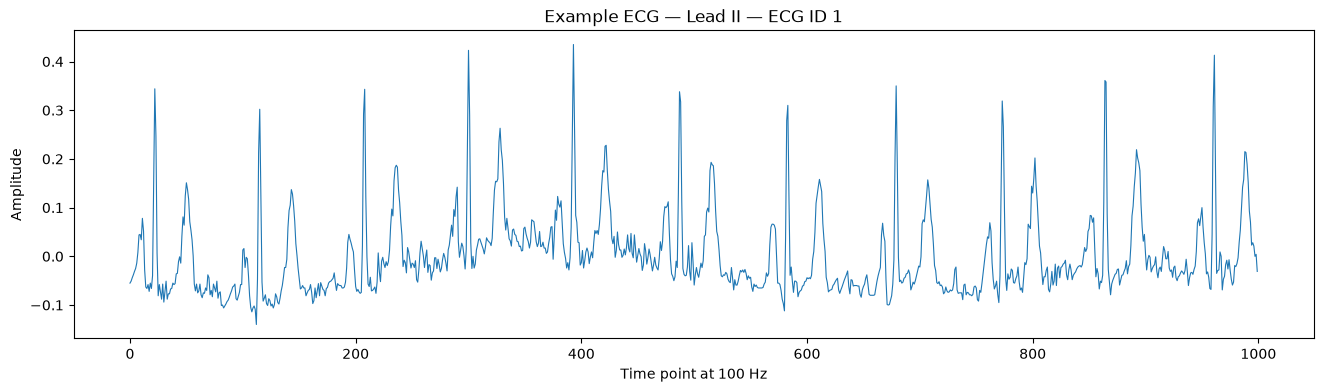

In [5]:
sample = labelled_metadata.iloc[0]

# filename_lr is the 100 Hz waveform path without .hea/.dat extension.
sample_path = PTBXL_DIR / sample["filename_lr"]

signal, signal_info = wfdb.rdsamp(str(sample_path))

print("ECG ID:", sample["ecg_id"])
print("Labels:", sample["diagnostic_classes"])
print("Signal shape:", signal.shape)
print("Expected shape: (1000 time points, 12 leads)")
print("Contains missing signal values:", np.isnan(signal).any())

lead_names = signal_info["sig_name"]

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(signal[:, 1], linewidth=0.8)
ax.set_title(f"Example ECG — Lead {lead_names[1]} — ECG ID {sample['ecg_id']}")
ax.set_xlabel("Time point at 100 Hz")
ax.set_ylabel("Amplitude")
plt.show()

In [6]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

manifest_columns = [
    "ecg_id",
    "patient_id",
    "filename_lr",
    "strat_fold",
    "split",
    "age",
    "sex",
    "height",
    "weight",
    "diagnostic_classes",
] + CLASSES

ecg_manifest = labelled_metadata[manifest_columns].copy()

ecg_manifest.to_csv(
    OUTPUT_DIR / "ptbxl_ecg_manifest.csv",
    index=False,
)

manifest_report = {
    "total_labelled_ecgs": int(len(ecg_manifest)),
    "train_records": int((ecg_manifest["split"] == "train").sum()),
    "validation_records": int((ecg_manifest["split"] == "validation").sum()),
    "test_records": int((ecg_manifest["split"] == "test").sum()),
    "classes": CLASSES,
    "sampling_rate_hz": 100,
    "time_points_per_record": 1000,
    "leads_per_record": 12,
}

with open(
    OUTPUT_DIR / "ecg_preprocessing_report.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(manifest_report, file, indent=2)

print("Saved:", OUTPUT_DIR / "ptbxl_ecg_manifest.csv")
display(pd.DataFrame([manifest_report]))

Saved: /home/niru/Nirma/Sem-3/ML/Assignment/code/data/processed/ptb-xl/ptbxl_ecg_manifest.csv


,total_labelled_ecgs,train_records,validation_records,test_records,classes,sampling_rate_hz,time_points_per_record,leads_per_record
0,21388,17084,2146,2158,"[NORM, MI, STTC, CD, HYP]",100,1000,12


In [7]:
from tqdm.auto import tqdm

train_manifest = ecg_manifest[
    ecg_manifest["split"] == "train"
].copy()

lead_sum = np.zeros(12, dtype=np.float64)
lead_squared_sum = np.zeros(12, dtype=np.float64)
total_time_points = 0

invalid_training_records = []

for row in tqdm(
    train_manifest.itertuples(index=False),
    total=len(train_manifest),
    desc="Reading training ECGs",
):
    waveform_path = PTBXL_DIR / row.filename_lr

    try:
        signal, _ = wfdb.rdsamp(str(waveform_path))

        valid_shape = signal.shape == (1000, 12)
        valid_values = np.isfinite(signal).all()

        if not valid_shape or not valid_values:
            invalid_training_records.append(row.ecg_id)
            continue

        lead_sum += signal.sum(axis=0)
        lead_squared_sum += np.square(signal).sum(axis=0)
        total_time_points += signal.shape[0]

    except Exception:
        invalid_training_records.append(row.ecg_id)

lead_mean = lead_sum / total_time_points
lead_variance = (lead_squared_sum / total_time_points) - np.square(lead_mean)
lead_std = np.sqrt(np.maximum(lead_variance, 1e-8))

normalization_table = pd.DataFrame(
    {
        "Lead": lead_names,
        "Training mean (mV)": lead_mean,
        "Training std (mV)": lead_std,
    }
)

print("Before vs after waveform-quality check:")
display(
    pd.DataFrame(
        {
            "Before": [len(train_manifest)],
            "After": [len(train_manifest) - len(invalid_training_records)],
        },
        index=["Training ECG records"],
    )
)

print(f"\nInvalid training ECG records: {len(invalid_training_records)}")
display(normalization_table)

Reading training ECGs:   0%|          | 0/17084 [00:00<?, ?it/s]

Before vs after waveform-quality check:


,Before,After
Training ECG records,17084,17084



Invalid training ECG records: 0


,Lead,Training mean (mV),Training std (mV)
0,I,-0.002,0.160
1,II,-0.002,0.159
2,III,0.000,0.160
3,AVR,0.002,0.138
4,AVL,-0.001,0.139
5,AVF,-0.001,0.138
6,V1,0.000,0.234
7,V2,-0.001,0.334
8,V3,-0.002,0.328
9,V4,-0.001,0.293


Lead comparison for ECG ID 1:


,Before normalization,After normalization
Mean,0.001,0.014
Standard deviation,0.083,0.523
Minimum,-0.140,-0.870
Maximum,0.435,2.741


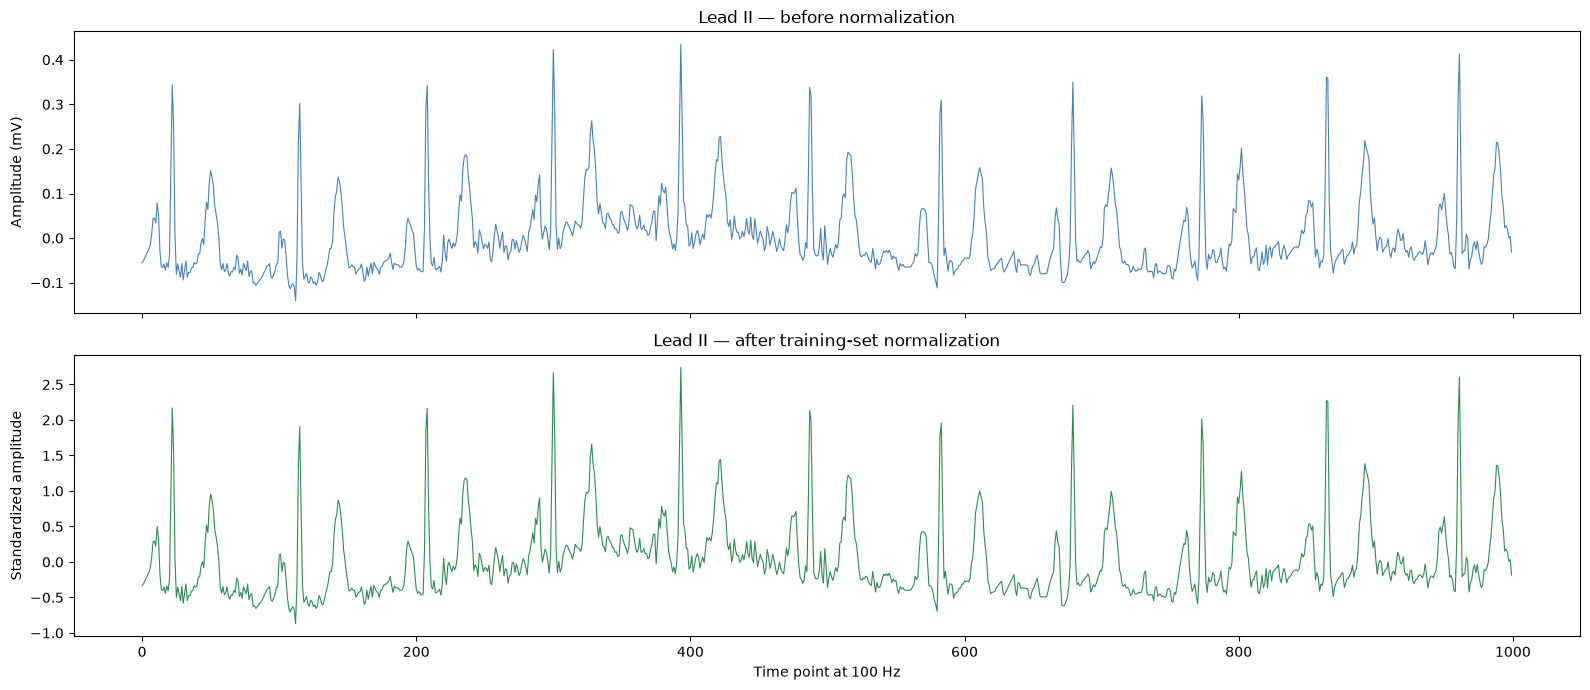

In [8]:
sample_train = train_manifest.iloc[0]

sample_signal, sample_info = wfdb.rdsamp(
    str(PTBXL_DIR / sample_train["filename_lr"])
)

normalized_signal = (sample_signal - lead_mean) / lead_std

lead_index = 1  # Lead II

comparison = pd.DataFrame(
    {
        "Before normalization": [
            sample_signal[:, lead_index].mean(),
            sample_signal[:, lead_index].std(),
            sample_signal[:, lead_index].min(),
            sample_signal[:, lead_index].max(),
        ],
        "After normalization": [
            normalized_signal[:, lead_index].mean(),
            normalized_signal[:, lead_index].std(),
            normalized_signal[:, lead_index].min(),
            normalized_signal[:, lead_index].max(),
        ],
    },
    index=["Mean", "Standard deviation", "Minimum", "Maximum"],
)

print(f"Lead comparison for ECG ID {sample_train['ecg_id']}:")
display(comparison)

fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

axes[0].plot(sample_signal[:, lead_index], linewidth=0.8, color="steelblue")
axes[0].set_title("Lead II — before normalization")
axes[0].set_ylabel("Amplitude (mV)")

axes[1].plot(normalized_signal[:, lead_index], linewidth=0.8, color="seagreen")
axes[1].set_title("Lead II — after training-set normalization")
axes[1].set_xlabel("Time point at 100 Hz")
axes[1].set_ylabel("Standardized amplitude")

plt.tight_layout()
plt.show()

In [9]:
np.savez(
    OUTPUT_DIR / "ecg_normalization_stats.npz",
    lead_names=np.array(lead_names),
    lead_mean=lead_mean,
    lead_std=lead_std,
)

normalization_report = {
    "normalization_method": "Training-set mean and standard deviation per ECG lead",
    "training_records_used": int(len(train_manifest) - len(invalid_training_records)),
    "invalid_training_records": int(len(invalid_training_records)),
    "sampling_rate_hz": 100,
    "time_points_per_ecg": 1000,
    "number_of_leads": 12,
    "lead_names": list(lead_names),
}

with open(
    OUTPUT_DIR / "ecg_normalization_report.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(normalization_report, file, indent=2)

print("Saved ECG normalization files:")
print("•", OUTPUT_DIR / "ecg_normalization_stats.npz")
print("•", OUTPUT_DIR / "ecg_normalization_report.json")

display(pd.DataFrame([normalization_report]))

Saved ECG normalization files:
• /home/niru/Nirma/Sem-3/ML/Assignment/code/data/processed/ptb-xl/ecg_normalization_stats.npz
• /home/niru/Nirma/Sem-3/ML/Assignment/code/data/processed/ptb-xl/ecg_normalization_report.json


,normalization_method,training_records_used,invalid_training_records,sampling_rate_hz,time_points_per_ecg,number_of_leads,lead_names
0,Training-set mean and standard deviation per E...,17084,0,100,1000,12,"[I, II, III, AVR, AVL, AVF, V1, V2, V3, V4, V5..."
